# Capítulo 5 · Proyecto 1: comparación de modelos

> ¿Qué modelo recomendarías para clasificar la presencia de enfermedad cardiaca y qué resultados respaldan tu elección?

Utiliza el dataset [UCI Heart Disease de Kaggle](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data), archivo `heart_disease_uci.csv`, y documenta tu trabajo en un notebook reproducible.

## Etapa 1: limpieza y preparación

1. Identifica los valores faltantes y los valores inválidos, decide cómo tratarlos y justifica brevemente tu decisión.
2. Explora los posibles outliers y explica si los conservarás o aplicarás algún tratamiento.
3. Prepara las variables numéricas y categóricas. Crea el objetivo binario (**target**) a partir de `num`: **target = 0 si num = 0** (ausencia de enfermedad) y **target = 1 si num es 1, 2, 3 o 4** (presencia de enfermedad). Excluye tanto `num` como el target de las entradas del modelo.

## Etapa 2: entrenamiento y comparación

1. Separa los datos en entrenamiento, validación y prueba, usando las mismas particiones para todos los modelos y `random_state=42`. Ajusta la imputación y el escalado únicamente con entrenamiento.
2. Entrena **regresión logística, KNN y árbol de decisión**, aplicando escalado cuando corresponda.
3. Usa **GridSearchCV** con validación cruzada sobre los datos de entrenamiento para buscar los mejores hiperparámetros de los tres modelos. Compara las mejores configuraciones en validación y selecciona el modelo con mejor resultado según una métrica justificada.
4. Compara entrenamiento y evaluación para identificar sobreajuste. Presenta una tabla de métricas y las matrices de confusión de prueba.
5. Recomienda un modelo y justifica tu elección con los resultados: qué errores comete, qué ventajas tiene y cuáles son sus limitaciones.

## Importacion de librerias

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

| Nombre original | Significado en español |
|---|---|
| `id` | Identificador del registro |
| `age` | Edad |
| `sex` | Sexo |
| `dataset` | Origen de los datos |
| `cp` | Tipo de dolor torácico |
| `trestbps` | Presión arterial en reposo |
| `chol` | Colesterol |
| `fbs` | Glucosa en ayunas superior a 120 mg/dL |
| `restecg` | Resultado del electrocardiograma en reposo |
| `thalch` | Frecuencia cardíaca máxima alcanzada |
| `exang` | Angina provocada por el ejercicio |
| `oldpeak` | Descenso del segmento ST durante el ejercicio respecto al reposo |
| `slope` | Pendiente del segmento ST durante el máximo esfuerzo |
| `ca` | Número de vasos principales observados por fluoroscopia |
| `thal` | Resultado de la prueba de talio |
| `num` | Diagnóstico: 0 indica ausencia de enfermedad; 1–4 indican presencia |

## Carga de datos

In [19]:
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "heart_disease_uci.csv")
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## Exploracion inicial

In [20]:
df.shape

(920, 16)

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [22]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [24]:
# 1. Revisión y eliminación de duplicados ignorando el identificador 'id'
cols_sin_id = df.columns.difference(["id"])
print("Duplicados clínicos (sin id):", df.duplicated(subset=cols_sin_id).sum())
df = df.drop_duplicates(subset=cols_sin_id).copy()
print("Dimensiones tras eliminar duplicados:", df.shape)

Duplicados clínicos (sin id): 2
Dimensiones tras eliminar duplicados: (918, 16)


In [25]:
# 2. Revisión de categorías para verificar que no existan errores tipográficos o espacios
cols_categoricas_todas = ["sex", "dataset", "cp", "fbs", "restecg", "exang", "slope", "thal"]
for col in cols_categoricas_todas:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- sex ---
sex
Male      725
Female    193
Name: count, dtype: int64 

--- dataset ---
dataset
Cleveland        304
Hungary          292
VA Long Beach    199
Switzerland      123
Name: count, dtype: int64 

--- cp ---
cp
asymptomatic       496
non-anginal        203
atypical angina    173
typical angina      46
Name: count, dtype: int64 

--- fbs ---
fbs
False    690
True     138
NaN       90
Name: count, dtype: int64 

--- restecg ---
restecg
normal              550
lv hypertrophy      188
st-t abnormality    178
NaN                   2
Name: count, dtype: int64 

--- exang ---
exang
False    527
True     336
NaN       55
Name: count, dtype: int64 

--- slope ---
slope
flat           345
NaN            307
upsloping      203
downsloping     63
Name: count, dtype: int64 

--- thal ---
thal
NaN                  484
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64 



In [26]:
# 3. Detección y conversión de valores inválidos (0 en presión arterial y colesterol) a NaN
print("Ceros inválidos en trestbps:", (df["trestbps"] == 0).sum())
print("Ceros inválidos en chol:    ", (df["chol"] == 0).sum())

df.loc[df["trestbps"] == 0, "trestbps"] = np.nan
df.loc[df["chol"] == 0, "chol"] = np.nan

Ceros inválidos en trestbps: 1
Ceros inválidos en chol:     172


In [27]:
# 4. Nuevo resumen de valores faltantes reales
resumen_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
}).sort_values("nulos", ascending=False)
resumen_nulos

,nulos,porcentaje
ca,609,66.34
thal,484,52.72
slope,307,33.44
chol,201,21.90
fbs,90,9.80
oldpeak,62,6.75
trestbps,60,6.54
thalch,55,5.99
exang,55,5.99
restecg,2,0.22


,variable,min,Q1,mediana,Q3,max,lim_inf_IQR,lim_sup_IQR,outliers_IQR,outliers_Z>3,asimetria_skew
0,age,28.0,47.0,54.0,60.0,77.0,27.50,79.50,0,0,-0.20
1,trestbps,80.0,120.0,130.0,140.0,200.0,90.00,170.00,27,7,0.63
2,chol,85.0,210.0,240.0,277.0,603.0,109.50,377.50,23,8,1.31
3,thalch,60.0,120.0,140.0,157.0,202.0,64.50,212.50,2,0,-0.21
4,oldpeak,-2.6,0.0,0.5,1.5,6.2,-2.25,3.75,16,7,1.04


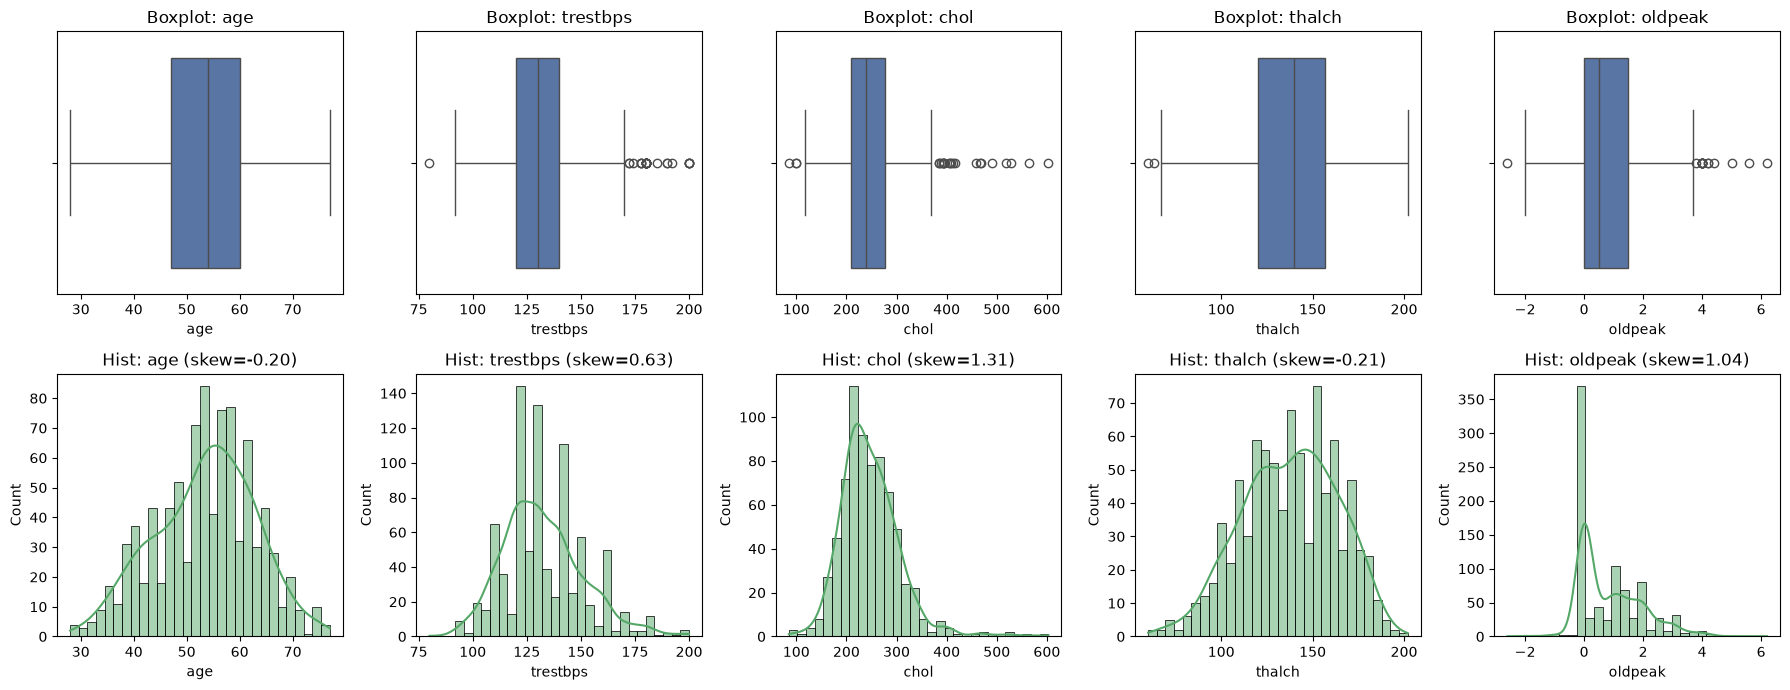

In [28]:
cols_num_continuas = ["age", "trestbps", "chol", "thalch", "oldpeak"]

def detectar_outliers_resumen(dataframe, columnas, k=1.5):
    """Calcula límites IQR, conteo de outliers por IQR y Z-score, y asimetría."""
    resultados = []
    for col in columnas:
        serie = dataframe[col].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - k * iqr, q3 + k * iqr
        out_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()
        z_scores = (serie - serie.mean()) / serie.std()
        out_z = (z_scores.abs() > 3).sum()
        
        resultados.append({
            "variable": col,
            "min": serie.min(),
            "Q1": q1,
            "mediana": serie.median(),
            "Q3": q3,
            "max": serie.max(),
            "lim_inf_IQR": round(lim_inf, 2),
            "lim_sup_IQR": round(lim_sup, 2),
            "outliers_IQR": out_iqr,
            "outliers_Z>3": out_z,
            "asimetria_skew": round(serie.skew(), 2)
        })
    return pd.DataFrame(resultados)

tabla_outliers = detectar_outliers_resumen(df, cols_num_continuas)
display(tabla_outliers)

# Visualización con Boxplots e Histogramas
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, col in enumerate(cols_num_continuas):
    sns.boxplot(x=df[col], ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"Boxplot: {col}")
    
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=axes[1, i], color="#55A868")
    axes[1, i].set_title(f"Hist: {col} (skew={df[col].skew():.2f})")

plt.tight_layout()
plt.show()

In [29]:
from sklearn import set_config
from sklearn.preprocessing import StandardScaler

# Para que los transformadores de scikit-learn devuelvan DataFrames con nombres de columnas
set_config(transform_output="pandas")

# 1. Creación del target binario: 0 si num == 0, 1 si num en {1, 2, 3, 4}
df["target"] = (df["num"] > 0).astype(int)

print("Distribución del target (conteo y proporción):")
display(pd.DataFrame({
    "conteo": df["target"].value_counts(),
    "porcentaje (%)": (df["target"].value_counts(normalize=True) * 100).round(2)
}))

# 2. Definir X e y excluyendo 'id', 'num' y 'target'
X = df.drop(columns=["id", "num", "target"])
y = df["target"]

# 3. Clasificación de columnas numéricas y categóricas
# (Aseguramos que las categóricas booleanas con NaN como 'fbs' y 'exang' tengan tipo string/object uniforme)
numericas = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
categoricas = ["sex", "dataset", "cp", "fbs", "restecg", "exang", "slope", "thal"]

X[categoricas] = X[categoricas].astype(object)

# 4. Construcción de los Pipelines de preprocesamiento para la Etapa 2
# (Se ajustarán con .fit() ÚNICAMENTE sobre X_train en la Etapa 2)
pipeline_num_escalado = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

pipeline_num_sin_escalar = Pipeline([
    ("imputador", SimpleImputer(strategy="median"))
])

pipeline_cat = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))
])

# Preprocesador para Regresión Logística y KNN (con escalado)
preprocesador_escalado = ColumnTransformer([
    ("num", pipeline_num_escalado, numericas),
    ("cat", pipeline_cat, categoricas)
])

# Preprocesador para Árbol de Decisión (sin escalado)
preprocesador_arbol = ColumnTransformer([
    ("num", pipeline_num_sin_escalar, numericas),
    ("cat", pipeline_cat, categoricas)
])

print("Variables de entrada (X):", X.shape)
preprocesador_escalado

Distribución del target (conteo y proporción):


,conteo,porcentaje (%)
target,,
1,508,55.34
0,410,44.66


Variables de entrada (X): (918, 14)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Separación en Entrenamiento (60%), Validación (20%) y Prueba (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=42
)  # 0.25 * 0.80 = 0.20 del total

print(f"Entrenamiento: {X_train.shape} ({len(X_train)/len(X):.1%}) | Proporción target=1: {y_train.mean():.4f}")
print(f"Validación:    {X_val.shape} ({len(X_val)/len(X):.1%}) | Proporción target=1: {y_val.mean():.4f}")
print(f"Prueba (Test): {X_test.shape} ({len(X_test)/len(X):.1%}) | Proporción target=1: {y_test.mean():.4f}")

Entrenamiento: (550, 14) (59.9%) | Proporción target=1: 0.5527
Validación:    (184, 14) (20.0%) | Proporción target=1: 0.5543
Prueba (Test): (184, 14) (20.0%) | Proporción target=1: 0.5543


In [31]:
def evaluar_modelo(nombre, pipe, X_tr, y_tr, X_v, y_v, X_te, y_te):
    """Calcula las métricas clave en Train, Validación y Prueba."""
    filas = []
    particiones = [("Train", X_tr, y_tr), ("Validación", X_v, y_v), ("Prueba (Test)", X_te, y_te)]
    for nombre_part, X_p, y_p in particiones:
        y_pred = pipe.predict(X_p)
        y_prob = pipe.predict_proba(X_p)[:, 1]
        filas.append({
            "Modelo": nombre,
            "Partición": nombre_part,
            "Accuracy": accuracy_score(y_p, y_pred),
            "Precision": precision_score(y_p, y_pred, zero_division=0),
            "Recall": recall_score(y_p, y_pred, zero_division=0),
            "F1-Score": f1_score(y_p, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_p, y_prob)
        })
    return pd.DataFrame(filas)

modelos_base = {
    "Regresión Logística (Base)": Pipeline([
        ("prep", clone(preprocesador_escalado)),
        ("modelo", LogisticRegression(random_state=42, max_iter=1000))
    ]),
    "KNN (Base)": Pipeline([
        ("prep", clone(preprocesador_escalado)),
        ("modelo", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Árbol de Decisión (Base)": Pipeline([
        ("prep", clone(preprocesador_arbol)),
        ("modelo", DecisionTreeClassifier(random_state=42))
    ])
}

resultados_base = []
for nombre, pipe in modelos_base.items():
    pipe.fit(X_train, y_train)
    resultados_base.append(evaluar_modelo(nombre, pipe, X_train, y_train, X_val, y_val, X_test, y_test))

df_resultados_base = pd.concat(resultados_base, ignore_index=True)
display(df_resultados_base.round(4))

,Modelo,Partición,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística (Base),Train,0.8382,0.8595,0.8454,0.8524,0.9100
1,Regresión Logística (Base),Validación,0.8424,0.8349,0.8922,0.8626,0.9022
2,Regresión Logística (Base),Prueba (Test),0.8478,0.8304,0.9118,0.8692,0.9332
3,KNN (Base),Train,0.8764,0.8806,0.8980,0.8893,0.9477
4,KNN (Base),Validación,0.8261,0.8365,0.8529,0.8447,0.8713
5,KNN (Base),Prueba (Test),0.8424,0.8349,0.8922,0.8626,0.8909
6,Árbol de Decisión (Base),Train,1.0000,1.0000,1.0000,1.0000,1.0000
7,Árbol de Decisión (Base),Validación,0.6739,0.7019,0.7157,0.7087,0.6688
8,Árbol de Decisión (Base),Prueba (Test),0.7554,0.7767,0.7843,0.7805,0.7519


In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

configuraciones_grid = {
    "Regresión Logística": {
        "pipeline": Pipeline([
            ("prep", clone(preprocesador_escalado)),
            ("modelo", LogisticRegression(random_state=42, max_iter=1000, solver="liblinear"))
        ]),
        "param_grid": {
            "modelo__C": [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
            "modelo__penalty": ["l1", "l2"],
            "modelo__class_weight": [None, "balanced"]
        }
    },
    "KNN": {
        "pipeline": Pipeline([
            ("prep", clone(preprocesador_escalado)),
            ("modelo", KNeighborsClassifier())
        ]),
        "param_grid": {
            "modelo__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
            "modelo__weights": ["uniform", "distance"],
            "modelo__p": [1, 2]  # 1: distancia Manhattan, 2: distancia Euclidiana
        }
    },
    "Árbol de Decisión": {
        "pipeline": Pipeline([
            ("prep", clone(preprocesador_arbol)),
            ("modelo", DecisionTreeClassifier(random_state=42))
        ]),
        "param_grid": {
            "modelo__max_depth": [2, 3, 4, 5, 6, 8, None],
            "modelo__min_samples_split": [2, 5, 10, 20],
            "modelo__min_samples_leaf": [1, 2, 5, 10],
            "modelo__criterion": ["gini", "entropy"]
        }
    }
}

mejores_modelos = {}
resultados_opt = []

for nombre, cfg in configuraciones_grid.items():
    grid = GridSearchCV(
        estimator=cfg["pipeline"],
        param_grid=cfg["param_grid"],
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
        refit=True
    )
    grid.fit(X_train, y_train)
    mejores_modelos[nombre] = grid.best_estimator_
    print(f"=== {nombre} ===")
    print("Mejores hiperparámetros:", grid.best_params_)
    print(f"Mejor ROC-AUC en CV (Train): {grid.best_score_:.4f}\n")
    
    resultados_opt.append(
        evaluar_modelo(f"{nombre} (Opt)", grid.best_estimator_, X_train, y_train, X_val, y_val, X_test, y_test)
    )

df_resultados_opt = pd.concat(resultados_opt, ignore_index=True)
display(df_resultados_opt.round(4))

/home/gossbosther/ml-course/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/gossbosther/ml-course/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/gossbosther/ml

=== Regresión Logística ===
Mejores hiperparámetros: {'modelo__C': 0.5, 'modelo__class_weight': None, 'modelo__penalty': 'l1'}
Mejor ROC-AUC en CV (Train): 0.8919

=== KNN ===
Mejores hiperparámetros: {'modelo__n_neighbors': 9, 'modelo__p': 1, 'modelo__weights': 'uniform'}
Mejor ROC-AUC en CV (Train): 0.8979

=== Árbol de Decisión ===
Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 2}
Mejor ROC-AUC en CV (Train): 0.8420



,Modelo,Partición,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística (Opt),Train,0.8345,0.8515,0.8487,0.8501,0.9087
1,Regresión Logística (Opt),Validación,0.8370,0.8333,0.8824,0.8571,0.9066
2,Regresión Logística (Opt),Prueba (Test),0.8533,0.8378,0.9118,0.8732,0.9344
3,KNN (Opt),Train,0.8473,0.8595,0.8651,0.8623,0.9309
4,KNN (Opt),Validación,0.8424,0.8349,0.8922,0.8626,0.8797
5,KNN (Opt),Prueba (Test),0.8424,0.8411,0.8824,0.8612,0.9096
6,Árbol de Decisión (Opt),Train,0.8382,0.8720,0.8289,0.8499,0.9062
7,Árbol de Decisión (Opt),Validación,0.7446,0.7957,0.7255,0.7590,0.8031
8,Árbol de Decisión (Opt),Prueba (Test),0.8370,0.8750,0.8235,0.8485,0.8678


,Modelo,Partición,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística (Base),Train,0.8382,0.8595,0.8454,0.8524,0.9100
1,Regresión Logística (Base),Validación,0.8424,0.8349,0.8922,0.8626,0.9022
2,Regresión Logística (Base),Prueba (Test),0.8478,0.8304,0.9118,0.8692,0.9332
3,KNN (Base),Train,0.8764,0.8806,0.8980,0.8893,0.9477
4,KNN (Base),Validación,0.8261,0.8365,0.8529,0.8447,0.8713
5,KNN (Base),Prueba (Test),0.8424,0.8349,0.8922,0.8626,0.8909
6,Árbol de Decisión (Base),Train,1.0000,1.0000,1.0000,1.0000,1.0000
7,Árbol de Decisión (Base),Validación,0.6739,0.7019,0.7157,0.7087,0.6688
8,Árbol de Decisión (Base),Prueba (Test),0.7554,0.7767,0.7843,0.7805,0.7519
9,Regresión Logística (Opt),Train,0.8345,0.8515,0.8487,0.8501,0.9087


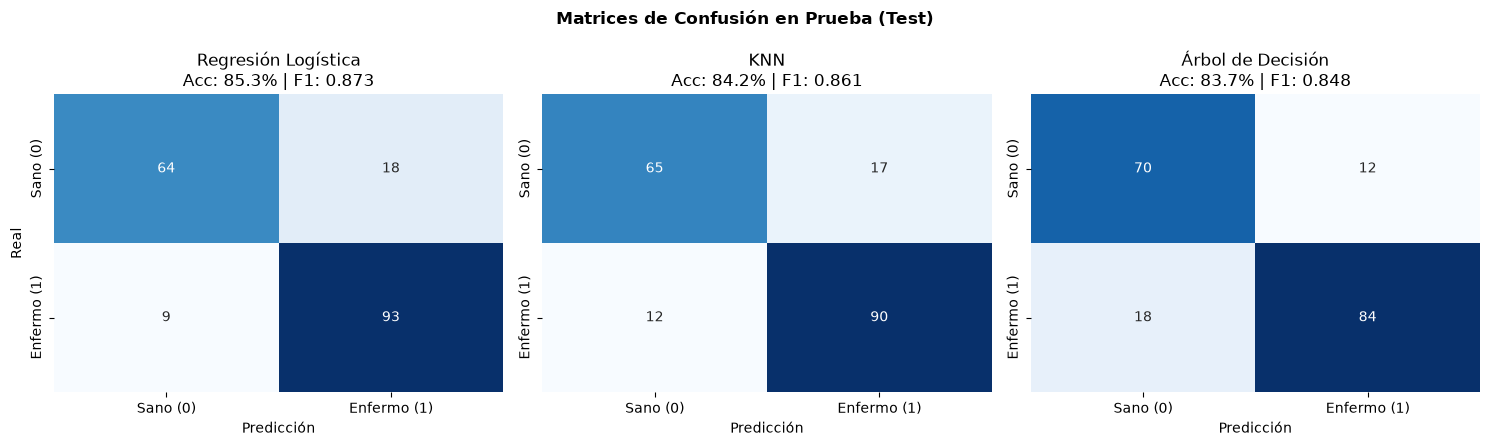

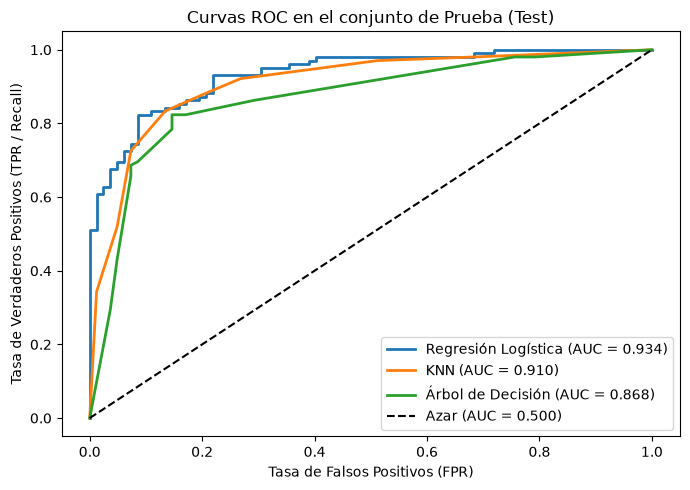

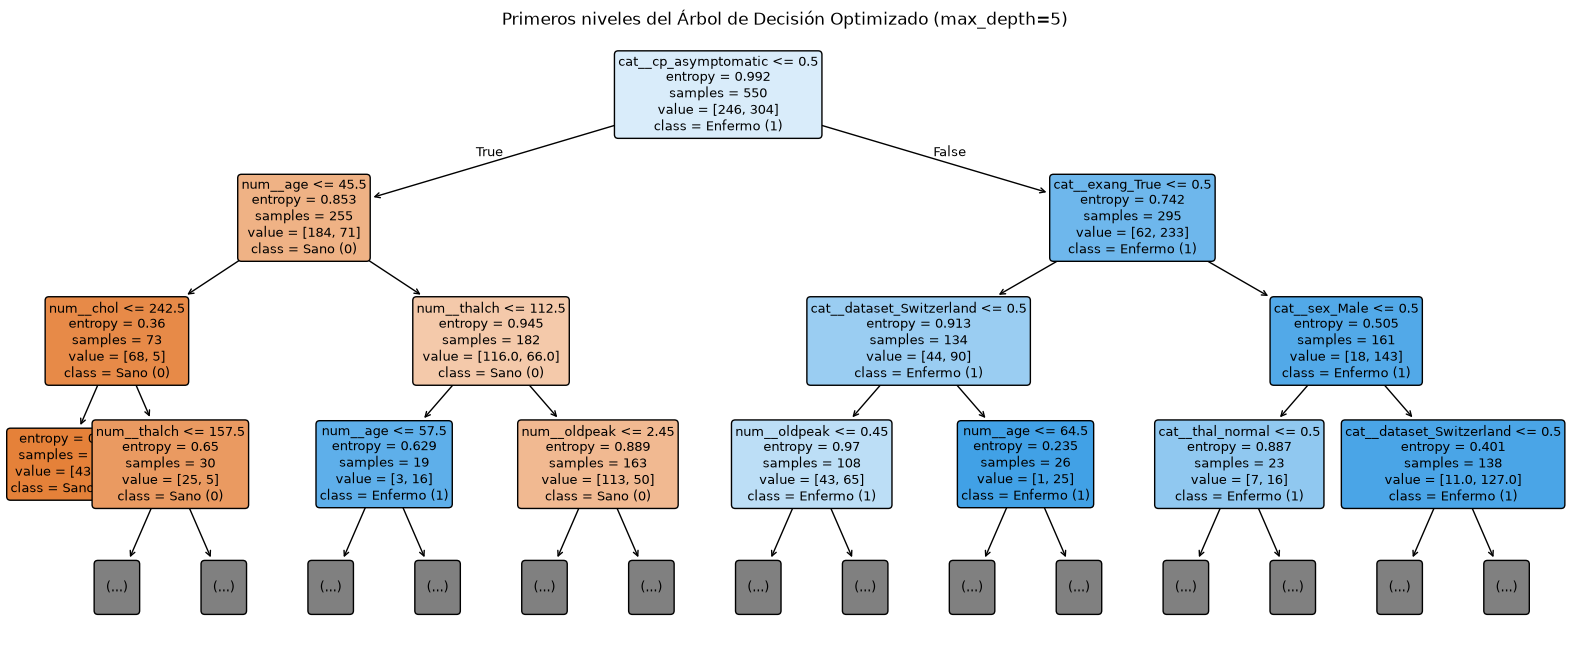

In [33]:
# 1. Tabla comparativa completa (Base vs Optimizados)
df_comparacion_total = pd.concat([df_resultados_base, df_resultados_opt], ignore_index=True)
display(df_comparacion_total.round(4))

# 2. Matrices de confusión de Prueba (Test) para los 3 modelos optimizados
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
etiquetas = ["Sano (0)", "Enfermo (1)"]

for ax, (nombre, pipe) in zip(axes, mejores_modelos.items()):
    y_pred_test = pipe.predict(X_test)
    matriz = confusion_matrix(y_test, y_pred_test)
    sns.heatmap(
        matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=etiquetas, yticklabels=etiquetas, ax=ax
    )
    ax.set_title(f"{nombre}\nAcc: {accuracy_score(y_test, y_pred_test):.1%} | F1: {f1_score(y_test, y_pred_test):.3f}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real" if ax == axes[0] else "")

plt.suptitle("Matrices de Confusión en Prueba (Test)", fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Curvas ROC en Prueba (Test)
plt.figure(figsize=(7, 5))
for nombre, pipe in mejores_modelos.items():
    y_prob_test = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob_test)
    auc_score = roc_auc_score(y_test, y_prob_test)
    plt.plot(fpr, tpr, linewidth=2, label=f"{nombre} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.500)")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
plt.title("Curvas ROC en el conjunto de Prueba (Test)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 4. Visualización del Árbol de Decisión optimizado (usando plot_tree importado al inicio)
arbol_entrenado = mejores_modelos["Árbol de Decisión"].named_steps["modelo"]
nombres_cols = mejores_modelos["Árbol de Decisión"].named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(20, 8))
plot_tree(
    arbol_entrenado, feature_names=nombres_cols, class_names=etiquetas,
    filled=True, rounded=True, max_depth=3, fontsize=9
)
plt.title("Primeros niveles del Árbol de Decisión Optimizado (max_depth=5)")
plt.show()